In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")
print(df.head())

# check missing values
print(df.isnull().sum())

         date  year  month  day         region    country category  \
0  2025-10-12  2025     10   12    Middle East        UAE  Chronic   
1  2020-09-15  2020      9   15     South Asia      India  Chronic   
2  2020-02-26  2020      2   26    Middle East        UAE  Vitamin   
3  2025-11-09  2025     11    9     South Asia  Sri Lanka  Chronic   
4  2022-04-04  2022      4    4  South America  Argentina  Chronic   

     medicine age_group  units_sold  unit_price  stock_level  \
0  Amlodipine      0-12         328       45.38         4774   
1  Amlodipine     26-45         371       75.49         4584   
2   Vitamin C      0-12         948       22.51         3934   
3  Amlodipine      0-12         275       63.29         4544   
4  Amlodipine     26-45         563       44.28         4284   

   expiry_days_remaining  covid_flag  
0                    466           0  
1                    181           1  
2                    556           1  
3                    330           0  

In [4]:
# divide sales into three categories
low = df["units_sold"].quantile(1/3)
high = df["units_sold"].quantile(2/3)

df["sales_class"] = np.select(
    [df["units_sold"] <= low, df["units_sold"] <= high],
    ["low", "medium"],
    default="high"
)

# display class distribution
print(df["sales_class"].value_counts())

sales_class
low       59651
high      59214
medium    59125
Name: count, dtype: int64


In [8]:
# separate features and target
X = df.drop(columns=["units_sold", "sales_class", "date"], errors="ignore")
y = df["sales_class"]

# remove rows with missing values
data = pd.concat([X, y], axis=1).dropna()
X = data.drop(columns="sales_class")
y = data["sales_class"]

# identify numerical and categorical columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

# split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
# encode categorical columns and scale numerical columns
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

# create logistic regression pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# train model
model.fit(X_train, y_train)

# predict test data
y_pred = model.predict(X_test)

# evaluate model
print("accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.6867239732569246
              precision    recall  f1-score   support

        high       0.80      0.78      0.79     11843
         low       0.73      0.75      0.74     11930
      medium       0.53      0.53      0.53     11825

    accuracy                           0.69     35598
   macro avg       0.69      0.69      0.69     35598
weighted avg       0.69      0.69      0.69     35598



In [10]:
# define regularization parameters
params = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__penalty": ["l1", "l2"],
    "classifier__solver": ["saga"]
}

# find the best model using cross-validation
grid = GridSearchCV(
    model, params, cv=3, scoring="f1_macro", n_jobs=-1
)

grid.fit(X_train, y_train)

# display best parameters
best_model = grid.best_estimator_
print("best parameters:", grid.best_params_)

best parameters: {'classifier__C': 0.01, 'classifier__penalty': 'l2', 'classifier__solver': 'saga'}


accuracy: 0.6879038148210573
              precision    recall  f1-score   support

        high       0.80      0.78      0.79     11843
         low       0.73      0.75      0.74     11930
      medium       0.54      0.53      0.53     11825

    accuracy                           0.69     35598
   macro avg       0.69      0.69      0.69     35598
weighted avg       0.69      0.69      0.69     35598



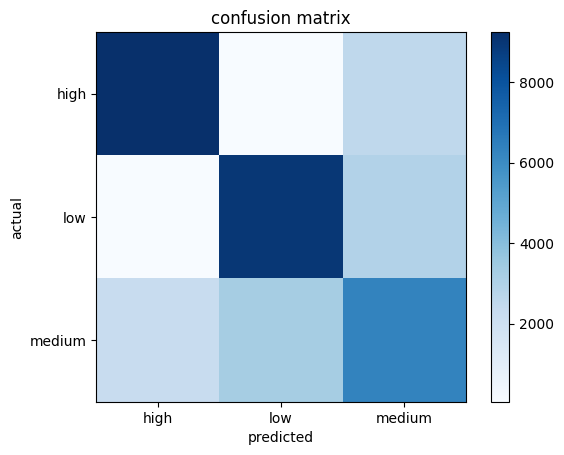

In [11]:
# predict using the tuned model
y_pred = best_model.predict(X_test)

# display evaluation metrics
print("accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(best_model.classes_)), best_model.classes_)
plt.yticks(range(len(best_model.classes_)), best_model.classes_)
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("confusion matrix")
plt.colorbar()
plt.show()

In [12]:
# extract feature names and model coefficients
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
classifier = best_model.named_steps["classifier"]

# display coefficients for each class
coef = pd.DataFrame(
    classifier.coef_,
    columns=feature_names,
    index=classifier.classes_
)
print(coef.round(3))

# calculate odds ratios relative to the low class
odds_ratio = np.exp(
    np.clip(coef.loc["high"] - coef.loc["low"], -50, 50)
)

print("\nodds ratios: high vs low")
print(odds_ratio.sort_values(ascending=False).round(3))

        cat__region_Africa  cat__region_East Asia  cat__region_Europe  \
high                -0.008                 -0.009              -0.007   
low                 -0.027                 -0.036              -0.027   
medium               0.035                  0.045               0.034   

        cat__region_Middle East  cat__region_North America  \
high                      0.001                     -0.011   
low                      -0.051                     -0.024   
medium                    0.051                      0.035   

        cat__region_Oceania  cat__region_South America  \
high                  0.007                      0.006   
low                  -0.044                     -0.033   
medium                0.037                      0.027   

        cat__region_South Asia  cat__country_Argentina  \
high                    -0.004                   -0.01   
low                     -0.048                   -0.01   
medium                   0.052                    0

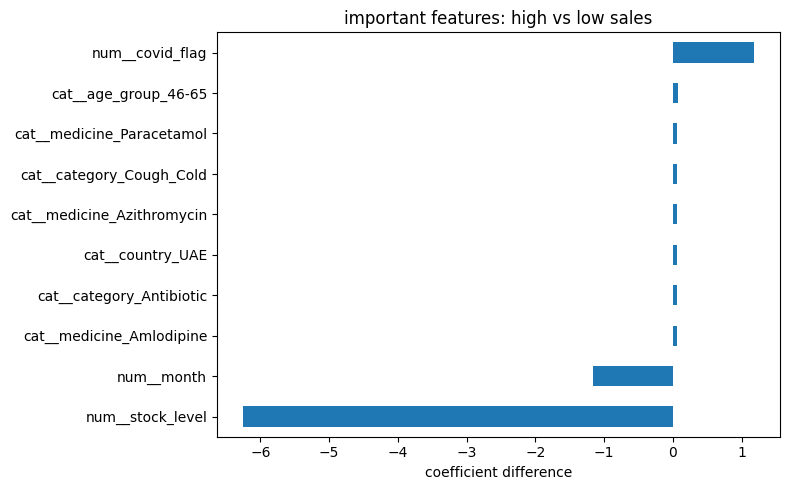

In [13]:
# select the 10 strongest coefficients for high vs low
top = (coef.loc["high"] - coef.loc["low"])
top = top.reindex(top.abs().sort_values(ascending=False).head(10).index)

# plot coefficient differences
top.sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("coefficient difference")
plt.title("important features: high vs low sales")
plt.tight_layout()
plt.show()